# 04c — LogisticRegression cân bằng làm đối chứng ưu tiên Recall

**Câu hỏi:** LogisticRegression cân bằng có đáng giữ khi ưu tiên phát hiện sinh viên nguy cơ ở cutoff 50% và 75%? Đây là đối chứng validation, không phải test độc lập.

Danh sách theo đuổi gồm CatBoost, XGBoost, LightGBM, HGB và LogisticRegression cân bằng. Những cấu hình bổ sung khác đã được bỏ khỏi notebook/bảng này; không suy ra cả họ thuật toán đó vô ích. Split theo sinh viên đã khóa từ notebook 02; tiền xử lý impute/one-hot/scale chỉ fit **trên train** trong pipeline.

In [1]:
from pathlib import Path
import sys, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
import sklearn

ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from NghienCuu_HCO_VNLS.code_dung_chung.thuc_nghiem import KET_QUA, HINH, nap_du_lieu, chon_dac_trung, tao_thu_muc
from clht_code.models import ModelConfig, make_pipeline
from clht_code.evaluation import metric_table, risk_probability

tao_thu_muc()
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.6.0


## 1. Nêu giả thuyết trước khi nhìn điểm

- **LogisticRegression:** đối chứng tuyến tính và dễ giải thích hơn, có thể có Recall cao khi dùng `class_weight=balanced` nhưng Accuracy ở ngưỡng mặc định thấp hơn.

Giữ cấu hình pilot đã thử, không tối ưu theo test cũ. HGB, CatBoost, XGBoost dùng pipeline/thiết lập riêng, nên bảng rộng là **so sánh cấu hình triển khai**, không quy mọi chênh lệch cho họ thuật toán.

In [2]:
CONFIGS = [
    ModelConfig('LogisticRegression_balanced', LogisticRegression(max_iter=700,
                       class_weight='balanced', random_state=41), scale=True),
]
rows = []
for cutoff in (.50, .75):
    frame = nap_du_lieu(cutoff)
    selected = chon_dac_trung(frame)
    train, valid = (frame.loc[frame.split == split].copy() for split in ('train', 'validation'))
    assert not (set(train.id_student) & set(valid.id_student))
    print(f'Cutoff {cutoff:.0%}: train {len(train)}, validation {len(valid)}, {len(selected)} đặc trưng')
    for config in CONFIGS:
        start = time.perf_counter()
        pipeline = make_pipeline(train[selected], config)
        pipeline.fit(train[selected], train.risk)
        probability = risk_probability(pipeline, valid[selected])
        metrics = metric_table(valid.risk, probability, .5)
        rows.append(dict(cutoff=cutoff, model=config.name, features=len(selected),
                         seconds=time.perf_counter()-start, **metrics))
        print(f'  {config.name:29s} Accuracy={metrics["accuracy"]:.4f}, Recall={metrics["recall_risk"]:.4f}, AP={metrics["average_precision_risk"]:.4f}')
results = pd.DataFrame(rows)
results.to_csv(KET_QUA / 'mo_hinh_thu_them_validation.csv', index=False, encoding='utf-8-sig')
display(results[['cutoff','model','features','accuracy','precision_risk','recall_risk',
                 'f1_risk','weighted_f1','average_precision_risk','seconds']].round(4))

Cutoff 50%: train 17310, validation 3638, 38 đặc trưng


  LogisticRegression_balanced   Accuracy=0.7971, Recall=0.7360, AP=0.8483
Cutoff 75%: train 16297, validation 3415, 38 đặc trưng


  LogisticRegression_balanced   Accuracy=0.8518, Recall=0.7901, AP=0.8949


,cutoff,model,features,accuracy,precision_risk,recall_risk,f1_risk,weighted_f1,average_precision_risk,seconds
0,0.50,LogisticRegression_balanced,38,0.7971,0.7339,0.7360,0.7349,0.7972,0.8483,0.4315
1,0.75,LogisticRegression_balanced,38,0.8518,0.7794,0.7901,0.7847,0.8521,0.8949,0.4089


## 2. Đặt cạnh những model đã chạy, nhưng đừng vội chọn “người thắng”

Bảng HGB và boosting trước đó dùng cùng tệp cutoff/split; đối chiếu trong **cùng mốc cutoff**. Bảng 04 được chạy lại sau khi cài CatBoost. Nhìn AP và Recall trước, kiểm tra Accuracy ở ngưỡng 0,5, rồi mới cân nhắc thời gian. Không trộn kết quả test cũ vào bước tìm ứng viên này.

,cutoff,model,accuracy,precision_risk,recall_risk,f1_risk,average_precision_risk,seconds
5,0.50,CatBoost,0.8153,0.8492,0.6281,0.7221,0.8548,16.4019
7,0.50,XGBoost,0.8164,0.8478,0.6331,0.7249,0.8528,0.5454
6,0.50,LightGBM,0.8153,0.8374,0.6410,0.7262,0.8526,0.4658
0,0.50,HGB_160,0.8134,0.8295,0.6439,0.7250,0.8505,NaN
20,0.50,LogisticRegression_balanced,0.7971,0.7339,0.7360,0.7349,0.8483,0.4315
17,0.75,CatBoost,0.8750,0.9120,0.7018,0.7932,0.9019,17.6499
19,0.75,XGBoost,0.8779,0.9157,0.7078,0.7985,0.9002,0.5127
18,0.75,LightGBM,0.8750,0.9139,0.7001,0.7928,0.8992,0.4237
4,0.75,HGB_160,0.8773,0.9174,0.7044,0.7969,0.8986,NaN
21,0.75,LogisticRegression_balanced,0.8518,0.7794,0.7901,0.7847,0.8949,0.4089


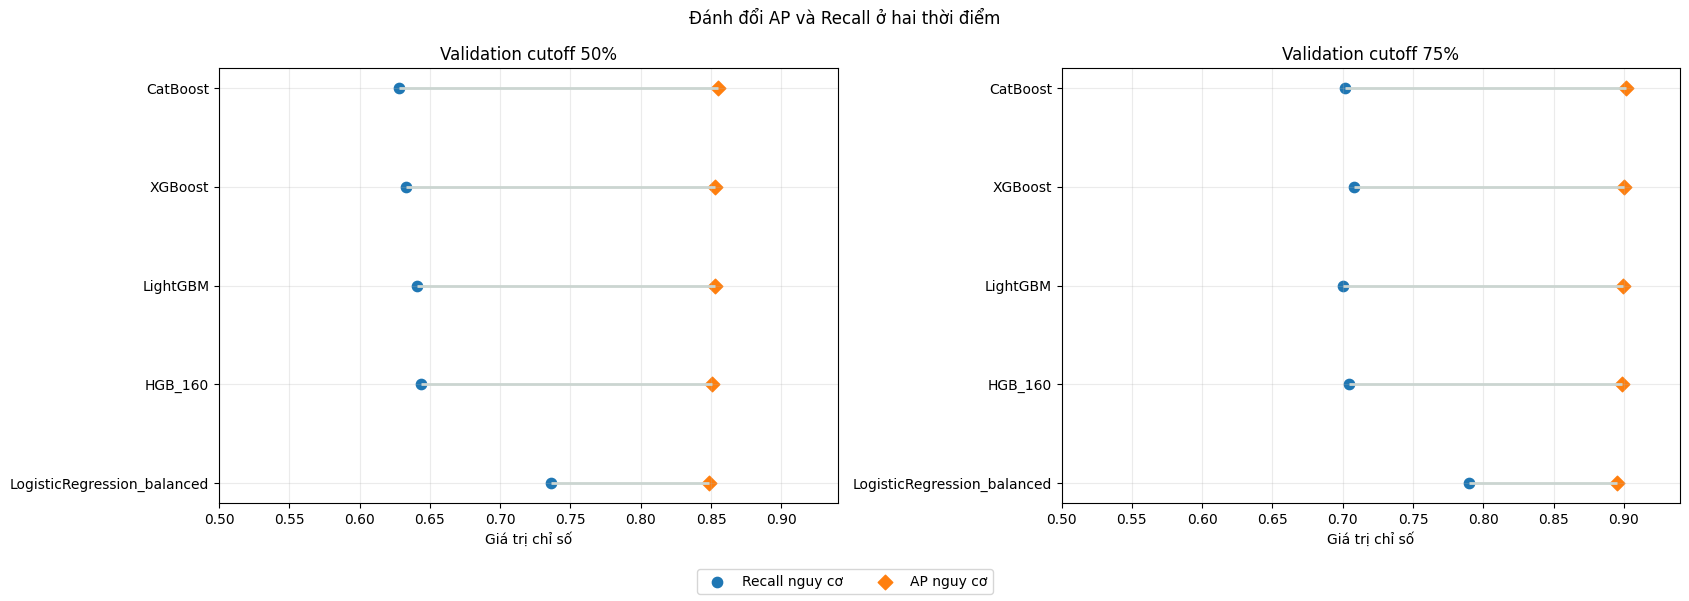

In [3]:
old_hgb = pd.read_csv(KET_QUA / 'hgb_theo_cutoff_validation.csv')
old_boosting = pd.read_csv(KET_QUA / 'boosting_validation.csv')
comparison = pd.concat([old_hgb, old_boosting, results], ignore_index=True)
comparison = comparison.loc[comparison.cutoff.isin((.50, .75)),
                            ['cutoff','model','accuracy','precision_risk','recall_risk','f1_risk','average_precision_risk','seconds']]
comparison = comparison.sort_values(['cutoff','average_precision_risk'], ascending=[True, False])
comparison.to_csv(KET_QUA / 'nam_mo_hinh_validation.csv', index=False, encoding='utf-8-sig')
display(comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharex=True)
for axis, cutoff in zip(axes, (.50, .75)):
    subset = comparison.loc[comparison.cutoff == cutoff]
    positions = list(range(len(subset)))
    axis.hlines(positions, subset.recall_risk, subset.average_precision_risk, color='#cbd5d1', linewidth=2)
    axis.scatter(subset.recall_risk, positions, s=55, label='Recall nguy cơ')
    axis.scatter(subset.average_precision_risk, positions, s=55, marker='D', label='AP nguy cơ')
    axis.set_yticks(positions, subset.model)
    axis.invert_yaxis()
    axis.set(title=f'Validation cutoff {cutoff:.0%}', xlabel='Giá trị chỉ số', xlim=(.50, .94))
    axis.grid(alpha=.25)
fig.suptitle('Đánh đổi AP và Recall ở hai thời điểm')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(HINH / 'thu_them_mo_hinh_validation.png', dpi=160, bbox_inches='tight')
plt.show()

## 3. Kết luận có giới hạn

**Quan sát thật ở validation:** LogisticRegression cân bằng đạt AP `0,8483`, Accuracy `0,7971`, Recall nguy cơ `0,7360` ở 50%; AP `0,8949`, Accuracy `0,8518`, Recall nguy cơ `0,7901` ở 75%. Recall cao hơn CatBoost 240 cây (`0,6281`/`0,7018`), nhưng Accuracy và AP thấp hơn. Đây là đánh đổi chứ không phải thắng mọi chỉ số.

Danh sách năm cấu hình được chốt sau khi đã nhìn nhiều ứng viên trên **cùng validation**, nên chênh lệch nhỏ có thể do may mắn. Lần kế tiếp cần lặp seed, kiểm tra theo nhóm sinh viên và đánh giá kỳ học mới. Tập test cũ đã được xem; **không** dùng nó để chọn lại. HCO/VNLS vẫn là trọng tâm chọn đặc trưng; notebook 05c thử trực tiếp ba cách tìm mask với CatBoost 80 cây.